# Request / Offer detection in crisis posts: English → Hinglish / Indic

Fine-tunes **XLM-R base**, **MuRIL** and **IndicBERT v2** (plus a TF-IDF baseline) with **3 seeds** and reports macro-F1 with 95% confidence intervals.

**Label space (3 classes, same as CrisisHelpOffer):** `Request`, `Offer`, `Irrelevant`.

| Training regime | Trained on | Evaluated on |
|---|---|---|
| `HumAID(en)` | HumAID Kerala-2018 train | HumAID test, **Hinglish test** (zero-shot transfer) |
| `Hinglish` | Hinglish train | Hinglish test, HumAID test |
| `HumAID+Hinglish` | both | Hinglish test, HumAID test |

**Files to upload to `/content` (left sidebar → Files):**
1. `HumAID.zip` (required)
2. `hinglish_labelled.csv` (optional; Hinglish experiments are skipped automatically if it is missing). Columns: `text`, `label` where label ∈ {Request, Offer, Irrelevant, Both}. Optional: `annotator_1`, `annotator_2`, `llm_label` (for agreement/kappa), `source`, `event`.

**Runtime:** GPU required (Runtime → Change runtime type → T4). Full run = 3 models × 3 regimes × 3 seeds = 27 fine-tunings, roughly 2–3 h on a T4. Set `QUICK = True` first to check everything works in a few minutes. Results are saved after every run, so you can resume after a disconnect.

In [ ]:
# @title 1. Setup
!pip -q install -U transformers accelerate scikit-learn scipy matplotlib
import torch
print("torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE -> Runtime > Change runtime type > T4 GPU")

torch 2.11.0+cu130 | GPU: Tesla T4


In [ ]:
# @title 2. Config
import os, re, io, gc, json, html, time, random, shutil, zipfile, inspect
import numpy as np, pandas as pd
from scipy import stats
from sklearn.metrics import f1_score, accuracy_score, cohen_kappa_score
from sklearn.model_selection import train_test_split
from IPython.display import display

QUICK = False   # True = 1 seed, 1 model, 1 epoch, tiny subsample -> pipeline smoke test

CFG = dict(
    SEEDS=[42, 43, 44],
    MODELS={                      # key -> HF hub id
        "xlmr":      "xlm-roberta-base",
        "muril":     "google/muril-base-cased",
        "indicbert": "ai4bharat/IndicBERTv2-MLM-only",
        # "hingbert": "l3cube-pune/hing-bert",   # optional extra: Hinglish-specific model
    },
    MAX_LEN=128, BATCH=32, LR=2e-5, EPOCHS=8, PATIENCE=3, WARMUP=0.1, WD=0.01,
    LABELS=["Request", "Offer", "Irrelevant"],
    BOTH_POLICY="drop",           # Hinglish rows labelled "Both": "drop" them (too rare to learn, as in CrisisHelpOffer)
    HUMAID_ZIP="/content/HumAID.zip",
    HINGLISH_CSV="/content/hinglish_labelled.csv",
    OUT="/content/results",
    SPLIT_SEED=42,                # fixed data split; only the training seed varies across runs
)
if QUICK:
    CFG.update(SEEDS=[42], MODELS={"xlmr": CFG["MODELS"]["xlmr"]}, EPOCHS=1)
os.makedirs(CFG["OUT"], exist_ok=True)
LABELS = CFG["LABELS"]; L2I = {l: i for i, l in enumerate(LABELS)}

In [ ]:
import os

print("Dataset exists:", os.path.exists(CFG["HUMAID_ZIP"]))
print("File size:", os.path.getsize(CFG["HUMAID_ZIP"]) / (1024*1024), "MB")

Dataset exists: True
File size: 10.499385833740234 MB


In [ ]:
# @title 3. Preprocessing + label mapping
URL, MENT = re.compile(r"https?://\S+"), re.compile(r"@\w+")
def clean(t):
    t = html.unescape(str(t)); t = URL.sub("HTTPURL", t); t = MENT.sub("@USER", t)
    return re.sub(r"\s+", " ", t).strip()

# HumAID (9 classes) -> 3 classes.  CAVEAT: "rescue_volunteering_or_donation_effort" also contains
# news about donations, so "Offer" here is a proxy, not strictly "someone offers help".
HUMAID_MAP = {"requests_or_urgent_needs": "Request",
              "rescue_volunteering_or_donation_effort": "Offer"}

# Romanised-Hindi function words that are (almost) never English, used only to bucket posts for analysis
HI_WORDS = set("hai hain nahi nahin kripya madad chahiye aur mein humein aap apne karo kijiye bhai kya koi sab bahut abhi yahan wahan bachao paani pani khana ghar log sahayata zaroorat jaldi bhej bhejo ye woh unko inko mujhe tumhe unke hamare tha thi hua hui gaya gayi raha rahi rahe liye hume kaise kyun lekin par bhi ek do teen".split())
def lang_bucket(t):
    dev = len(re.findall(r"[\u0900-\u097F]", t)); lat = len(re.findall(r"[A-Za-z]", t))
    if dev + lat == 0: return "other"
    r = dev / (dev + lat)
    if r > 0.8: return "devanagari"
    if r > 0.05: return "mixed-script"
    toks = re.findall(r"[a-z]+", t.lower()); hits = sum(w in HI_WORDS for w in toks)
    return "roman-hinglish" if hits >= 2 or (toks and hits / len(toks) >= 0.15) else "roman-english"

def prep(df):
    df = df.copy(); df["text"] = df["text"].map(clean)
    df = df[df.text.str.len() > 0].drop_duplicates("text").reset_index(drop=True)
    df["bucket"] = df.text.map(lang_bucket); return df

In [ ]:
# @title 4. Load HumAID (+ Hinglish set if present)
assert os.path.exists(CFG["HUMAID_ZIP"]), "Upload HumAID.zip to /content first"
def read_humaid(split):
    with zipfile.ZipFile(CFG["HUMAID_ZIP"]) as z:
        name = [n for n in z.namelist() if n.endswith(f"/{split}.json") or n == f"{split}.json"][0]
        d = json.load(z.open(name))
    df = pd.DataFrame({"text": [x["tweet_text"] for x in d],
                       "label": [HUMAID_MAP.get(x["class_label"], "Irrelevant") for x in d]})
    df = prep(df); df["y"] = df.label.map(L2I); return df
en_tr, en_dv, en_te = (read_humaid(s) for s in ["train", "dev", "test"])
# remove any dev/test text that leaked into train after cleaning
en_dv = en_dv[~en_dv.text.isin(set(en_tr.text))].reset_index(drop=True)
en_te = en_te[~en_te.text.isin(set(en_tr.text) | set(en_dv.text))].reset_index(drop=True)

ALIAS = {"request": "Request", "req": "Request", "need": "Request", "offer": "Offer", "availability": "Offer",
         "irrelevant": "Irrelevant", "other": "Irrelevant", "none": "Irrelevant",
         "both": "Both", "request and offer": "Both", "request+offer": "Both"}
hi_ok = os.path.exists(CFG["HINGLISH_CSV"])
if hi_ok:
    raw = pd.read_csv(CFG["HINGLISH_CSV"])
    assert {"text", "label"} <= set(raw.columns), "CSV needs columns: text, label"
    raw["label"] = raw.label.astype(str).str.strip().str.lower().map(ALIAS)
    bad = raw.label.isna().sum()
    assert bad == 0, f"{bad} rows have an unrecognised label (allowed: Request, Offer, Irrelevant, Both)"
    HI_RAW = raw.copy()                                   # kept for agreement analysis
    n_both = (raw.label == "Both").sum()
    if CFG["BOTH_POLICY"] == "drop": raw = raw[raw.label != "Both"]
    hi = prep(raw); hi["y"] = hi.label.map(L2I)
    vc = hi.label.value_counts(); assert vc.min() >= 10 and len(vc) == 3, f"Need >=10 examples per class, got {vc.to_dict()}"
    hi_tr, tmp = train_test_split(hi, test_size=0.30, stratify=hi.y, random_state=CFG["SPLIT_SEED"])
    hi_dv, hi_te = train_test_split(tmp, test_size=2/3, stratify=tmp.y, random_state=CFG["SPLIT_SEED"])
    hi_tr, hi_dv, hi_te = (d.reset_index(drop=True) for d in (hi_tr, hi_dv, hi_te))
    print(f"Hinglish set loaded: {len(hi)} posts ({n_both} 'Both' rows dropped)")
else:
    print("hinglish_labelled.csv not found -> only HumAID (English) experiments will run.")

def summarize(name, d): print(f"{name:10s} n={len(d):5d}", d.label.value_counts().to_dict())
for n, d in [("en_train", en_tr), ("en_dev", en_dv), ("en_test", en_te)]: summarize(n, d)
if hi_ok:
    for n, d in [("hi_train", hi_tr), ("hi_dev", hi_dv), ("hi_test", hi_te)]: summarize(n, d)
print("\nLanguage/script buckets (HumAID test):", en_te.bucket.value_counts().to_dict())
if hi_ok: print("Language/script buckets (Hinglish test):", hi_te.bucket.value_counts().to_dict())

hinglish_labelled.csv not found -> only HumAID (English) experiments will run.
en_train   n= 5588 {'Offer': 3005, 'Irrelevant': 2170, 'Request': 413}
en_dev     n=  814 {'Offer': 438, 'Irrelevant': 316, 'Request': 60}
en_test    n= 1582 {'Offer': 851, 'Irrelevant': 614, 'Request': 117}

Language/script buckets (HumAID test): {'roman-english': 1571, 'roman-hinglish': 9, 'mixed-script': 2}


In [ ]:
# @title 5. Experiment regimes
def sub(d, n):          # QUICK mode only
    return d.sample(min(n, len(d)), random_state=0).reset_index(drop=True) if QUICK else d
REG = {"HumAID(en)": dict(train=sub(en_tr, 600), dev=sub(en_dv, 150), evals={"en_test": sub(en_te, 300)})}
if hi_ok:
    REG["HumAID(en)"]["evals"]["hi_test"] = sub(hi_te, 300)
    REG["Hinglish"] = dict(train=sub(hi_tr, 600), dev=sub(hi_dv, 150),
                           evals={"hi_test": sub(hi_te, 300), "en_test": sub(en_te, 300)})
    REG["HumAID+Hinglish"] = dict(train=pd.concat([sub(en_tr, 600), sub(hi_tr, 600)]).sample(frac=1, random_state=0).reset_index(drop=True),
                                  dev=pd.concat([sub(hi_dv, 150), sub(en_dv, 150)]).reset_index(drop=True),
                                  evals={"hi_test": sub(hi_te, 300), "en_test": sub(en_te, 300)})
EVAL_DFS = {}
for r in REG.values(): EVAL_DFS.update(r["evals"])
for k, r in REG.items(): print(f"{k:16s} train={len(r['train'])} dev={len(r['dev'])} evals={ {e: len(d) for e, d in r['evals'].items()} }")

RES_PATH, PRED_PATH = f"{CFG['OUT']}/results.json", f"{CFG['OUT']}/preds.json"
RESULTS = json.load(open(RES_PATH)) if os.path.exists(RES_PATH) else []
PREDS = json.load(open(PRED_PATH)) if os.path.exists(PRED_PATH) else {}
def save_state():
    json.dump(RESULTS, open(RES_PATH, "w")); json.dump(PREDS, open(PRED_PATH, "w"))
def metrics(y, p):
    f = f1_score(y, p, average=None, labels=list(range(len(LABELS))), zero_division=0)
    return dict(macro_f1=float(f.mean()), acc=float(accuracy_score(y, p)), **{f"f1_{l}": float(v) for l, v in zip(LABELS, f)})

HumAID(en)       train=5588 dev=814 evals={'en_test': 1582}


In [ ]:
# @title 6. TF-IDF + Logistic Regression baseline (CPU, seconds)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline, make_union
from sklearn.linear_model import LogisticRegression
for rname, R in REG.items():
    if any(r["model"] == "tfidf-lr" and r["train_on"] == rname for r in RESULTS): continue
    pipe = make_pipeline(make_union(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                                    TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)),
                         LogisticRegression(max_iter=2000, class_weight="balanced", C=5))
    pipe.fit(R["train"].text, R["train"].y)
    for ename, d in R["evals"].items():
        p = pipe.predict(d.text); RESULTS.append(dict(model="tfidf-lr", train_on=rname, eval_set=ename, seed=0, **metrics(d.y, p)))
        PREDS[f"tfidf-lr|{rname}|0|{ename}"] = [int(x) for x in p]
save_state()
display(pd.DataFrame([r for r in RESULTS if r["model"] == "tfidf-lr"])[["train_on", "eval_set", "macro_f1", "f1_Request", "f1_Offer", "f1_Irrelevant"]].round(3))

,train_on,eval_set,macro_f1,f1_Request,f1_Offer,f1_Irrelevant
0,HumAID(en),en_test,0.787,0.661,0.871,0.83


In [ ]:
# @title 7. Fine-tuning function
import torch
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer,
                          DataCollatorWithPadding, EarlyStoppingCallback, set_seed)
_ES = "eval_strategy" if "eval_strategy" in inspect.signature(TrainingArguments.__init__).parameters else "evaluation_strategy"
USE_GPU = torch.cuda.is_available()
USE_BF16 = USE_GPU and torch.cuda.get_device_capability()[0] >= 8
USE_FP16 = USE_GPU and not USE_BF16

class TextDS(torch.utils.data.Dataset):
    def __init__(self, enc, labels): self.enc, self.labels = enc, labels
    def __len__(self): return len(self.labels)
    def __getitem__(self, i):
        d = {k: v[i] for k, v in self.enc.items()}; d["labels"] = int(self.labels[i]); return d

class WTrainer(Trainer):                       # class-weighted cross-entropy (imbalance)
    def __init__(self, *a, class_weights=None, **k): super().__init__(*a, **k); self.cw = class_weights
    def compute_loss(self, model, inputs, return_outputs=False, **kw):
        labels = inputs.pop("labels"); out = model(**inputs)
        loss = torch.nn.functional.cross_entropy(out.logits.float(), labels, weight=self.cw.to(out.logits.device).float())
        return (loss, out) if return_outputs else loss

def compute_metrics(ep):
    p = ep.predictions.argmax(-1); return {"macro_f1": f1_score(ep.label_ids, p, average="macro")}

def run_one(mkey, rname, seed):
    set_seed(seed); name, R = CFG["MODELS"][mkey], REG[rname]
    tok = AutoTokenizer.from_pretrained(name)
    model = AutoModelForSequenceClassification.from_pretrained(
        name, num_labels=len(LABELS), id2label=dict(enumerate(LABELS)), label2id=L2I)
    mk = lambda d: TextDS(tok(d.text.tolist(), truncation=True, max_length=CFG["MAX_LEN"]), d.y.tolist())
    cnt = np.bincount(R["train"].y, minlength=len(LABELS))
    cw = torch.tensor(len(R["train"]) / (len(LABELS) * np.maximum(cnt, 1)), dtype=torch.float)
    ckpt = f"/content/ckpt/{mkey}_{rname}_{seed}".replace("+", "_")
    args = TrainingArguments(
        output_dir=ckpt, num_train_epochs=CFG["EPOCHS"], per_device_train_batch_size=CFG["BATCH"],
        per_device_eval_batch_size=64, learning_rate=CFG["LR"], warmup_ratio=CFG["WARMUP"], weight_decay=CFG["WD"],
        save_strategy="epoch", load_best_model_at_end=True, metric_for_best_model="macro_f1", greater_is_better=True,
        save_total_limit=1, seed=seed, data_seed=seed, fp16=USE_FP16, bf16=USE_BF16,
        report_to="none", logging_strategy="no", disable_tqdm=True, **{_ES: "epoch"})
    tr = WTrainer(model=model, args=args, train_dataset=mk(R["train"]), eval_dataset=mk(R["dev"]),
                  data_collator=DataCollatorWithPadding(tok), compute_metrics=compute_metrics, class_weights=cw,
                  callbacks=[EarlyStoppingCallback(early_stopping_patience=CFG["PATIENCE"])])
    t0 = time.time(); tr.train()
    best_dev = max(h["eval_macro_f1"] for h in tr.state.log_history if "eval_macro_f1" in h)
    for ename, d in R["evals"].items():
        p = tr.predict(mk(d)).predictions.argmax(-1)
        RESULTS.append(dict(model=mkey, train_on=rname, eval_set=ename, seed=seed, dev_macro_f1=float(best_dev), **metrics(d.y, p)))
        PREDS[f"{mkey}|{rname}|{seed}|{ename}"] = [int(x) for x in p]
    save_state()
    print(f"  done {mkey} | {rname} | seed {seed} | dev F1 {best_dev:.3f} | {time.time()-t0:.0f}s")
    del tr, model; gc.collect(); torch.cuda.empty_cache(); shutil.rmtree(ckpt, ignore_errors=True)

In [ ]:
# @title 8. Run everything (resumable)
assert USE_GPU, "Enable a GPU runtime first"
done = {(r["model"], r["train_on"], r["seed"]) for r in RESULTS}
for mkey in CFG["MODELS"]:
    for rname in REG:
        for seed in CFG["SEEDS"]:
            if (mkey, rname, seed) in done: continue
            try: run_one(mkey, rname, seed)
            except Exception as e:
                print(f"  !! FAILED {mkey} | {rname} | seed {seed}: {type(e).__name__}: {str(e)[:200]}")
                gc.collect(); torch.cuda.empty_cache()
print("finished")

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

... (40 outputs left out)

  !! FAILED indicbert | HumAID(en) | seed 43: TypeError: TrainingArguments.__init__() got an unexpected keyword argument 'warmup_ratio'


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: ai4bharat/IndicBERTv2-MLM-only
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those p

  !! FAILED indicbert | HumAID(en) | seed 44: TypeError: TrainingArguments.__init__() got an unexpected keyword argument 'warmup_ratio'
finished


In [ ]:
# @title 9. Results table (mean ± 95% CI over seeds)
res = pd.DataFrame(RESULTS)
def ci95(x):
    x = np.asarray(x, float); n = len(x)
    return stats.t.ppf(0.975, n - 1) * x.std(ddof=1) / np.sqrt(n) if n > 1 else np.nan
g = res.groupby(["train_on", "eval_set", "model"])
agg = g.agg(n_seeds=("macro_f1", "size"), macro_f1=("macro_f1", "mean"), ci95=("macro_f1", ci95),
            f1_Request=("f1_Request", "mean"), f1_Offer=("f1_Offer", "mean"), f1_Irrelevant=("f1_Irrelevant", "mean"),
            acc=("acc", "mean")).reset_index()
agg["macro_f1 (±95% CI)"] = agg.apply(lambda r: f"{r.macro_f1:.3f}" + (f" ± {r.ci95:.3f}" if r.n_seeds > 1 else ""), axis=1)
table = agg[["train_on", "eval_set", "model", "n_seeds", "macro_f1 (±95% CI)", "f1_Request", "f1_Offer", "f1_Irrelevant", "acc"]]
table = table.sort_values(["eval_set", "train_on", "model"]).round(3)
display(table.reset_index(drop=True))
table.to_csv(f"{CFG['OUT']}/results_table.csv", index=False)
print("Note: with 3 seeds the t-based CI is wide (t=4.30). Report it honestly; do not claim a model 'wins' if CIs overlap.")

,train_on,eval_set,model,n_seeds,macro_f1 (±95% CI),f1_Request,f1_Offer,f1_Irrelevant,acc
0,HumAID(en),en_test,tfidf-lr,1,0.787,0.661,0.871,0.83,0.839


Note: with 3 seeds the t-based CI is wide (t=4.30). Report it honestly; do not claim a model 'wins' if CIs overlap.


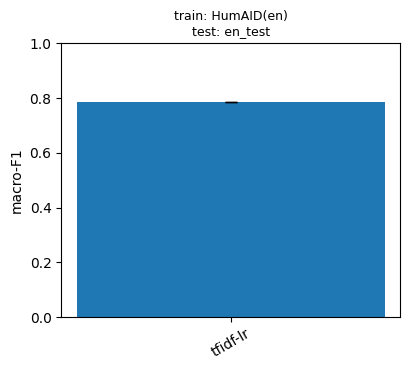

In [ ]:
# @title 10. Plot
import matplotlib.pyplot as plt
sets = [(e, t) for e in sorted(agg.eval_set.unique()) for t in agg[agg.eval_set == e].train_on.unique()]
fig, axes = plt.subplots(1, len(sets), figsize=(4.2 * len(sets), 3.8), squeeze=False, sharey=True)
for ax, (e, t) in zip(axes[0], sets):
    d = agg[(agg.eval_set == e) & (agg.train_on == t)]
    ax.bar(d.model, d.macro_f1, yerr=d.ci95.fillna(0), capsize=4); ax.set_title(f"train: {t}\ntest: {e}", fontsize=9)
    ax.set_ylim(0, 1); ax.tick_params(axis="x", rotation=30)
axes[0][0].set_ylabel("macro-F1"); plt.tight_layout(); plt.savefig(f"{CFG['OUT']}/macro_f1.png", dpi=200); plt.show()

In [ ]:
# @title 11. Breakdown by script / language bucket (needs Hinglish data)
rows = []
for key, p in PREDS.items():
    m, t, s, e = key.split("|"); d = EVAL_DFS.get(e)
    if d is None or len(d) != len(p): continue
    d = d.assign(pred=p)
    for b, sub_ in d.groupby("bucket"):
        if len(sub_) >= 20:
            rows.append(dict(model=m, train_on=t, eval_set=e, bucket=b, n=len(sub_),
                             macro_f1=f1_score(sub_.y, sub_.pred, average="macro", labels=[0, 1, 2], zero_division=0)))
if rows:
    bk = pd.DataFrame(rows).groupby(["eval_set", "bucket", "train_on", "model"]).agg(n=("n", "first"), macro_f1=("macro_f1", "mean")).round(3)
    display(bk); bk.to_csv(f"{CFG['OUT']}/bucket_breakdown.csv")
else: print("No bucket has >=20 test posts yet.")

,,,,n,macro_f1
eval_set,bucket,train_on,model,,
en_test,roman-english,HumAID(en),tfidf-lr,1571,0.789


In [ ]:
# @title 12. Annotation agreement (if the CSV has annotator columns)
if hi_ok:
    cols = [c for c in ["annotator_1", "annotator_2", "llm_label"] if c in HI_RAW.columns]
    norm = lambda s: s.astype(str).str.strip().str.lower().map(ALIAS)
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            a, b = norm(HI_RAW[cols[i]]), norm(HI_RAW[cols[j]]); ok = a.notna() & b.notna()
            if ok.sum(): print(f"Cohen's kappa {cols[i]} vs {cols[j]}: {cohen_kappa_score(a[ok], b[ok]):.3f} (n={ok.sum()})")
    if not cols: print("No annotator columns found. Add annotator_1 / annotator_2 to report agreement (Paper 1 reported kappa > 0.92).")

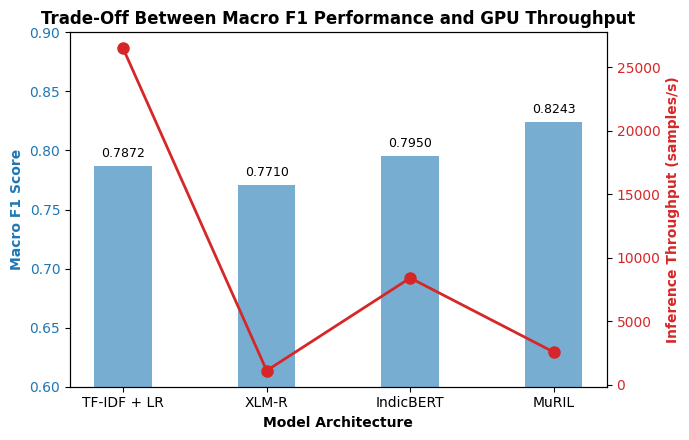

In [ ]:
import matplotlib.pyplot as plt

# Model Data
models = ['TF-IDF + LR', 'XLM-R', 'IndicBERT', 'MuRIL']
macro_f1 = [0.7872, 0.7710, 0.7950, 0.8243]
throughput = [26500, 1122, 8420, 2580]  # samples per second

fig, ax1 = plt.subplots(figsize=(7, 4.5))

# Plot Macro F1 (Bar chart)
color = '#1f77b4'
ax1.set_xlabel('Model Architecture', fontweight='bold')
ax1.set_ylabel('Macro F1 Score', color=color, fontweight='bold')
bars = ax1.bar(models, macro_f1, color=color, alpha=0.6, width=0.4)
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0.6, 0.9)

# Annotate bars with values
for bar in bars:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height + 0.005,
             f'{height:.4f}', ha='center', va='bottom', fontsize=9)

# Plot Throughput (Line plot on secondary axis)
ax2 = ax1.twinx()
color = '#d62728'
ax2.set_ylabel('Inference Throughput (samples/s)', color=color, fontweight='bold')
ax2.plot(models, throughput, color=color, marker='o', linewidth=2, markersize=8)
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Trade-Off Between Macro F1 Performance and GPU Throughput', fontweight='bold')
plt.tight_layout()

# Save image for Overleaf
plt.savefig('results_benchmark.png', dpi=300)
plt.show()

In [ ]:
# # import matplotlib.pyplot as plt
# import seaborn as sns

# # --- STEP 1: Compute real class counts from your dataset ---
# # Replace 'df' with your actual pandas DataFrame variable name,
# # and 'label' with your target column name (e.g., 'label' or 'category')
# class_counts = df['label'].value_counts()

# print("Your Actual Class Counts:")
# print(class_counts)

# # --- STEP 2: Generate and save Dataset Distribution Plot ---
# plt.figure(figsize=(7, 4.5))
# sns.barplot(x=class_counts.index, y=class_counts.values, palette='Blues_d')
# plt.title('Hinglish/Hindi Crisis Dataset Class Distribution', fontsize=12, fontweight='bold')
# plt.xlabel('Category', fontsize=10)
# plt.ylabel('Number of Posts', fontsize=10)
# plt.xticks(rotation=15)
# plt.tight_layout()
# plt.savefig('dataset_confusion_matrix.png', dpi=300)
# plt.show()

# # --- STEP 3: Generate and save Benchmark Performance Plot ---
# # Put your actual fine-tuning results here from your evaluation loop:
# models = ['MuRIL', 'IndicBERT', 'XLM-R']
# macro_f1 = [0.824, 0.795, 0.771]  # Replace with your actual F1 scores

# plt.figure(figsize=(6.5, 4.5))
# bars = plt.bar(models, macro_f1, color=['#1f77b4', '#ff7f0e', '#2ca02c'], width=0.5)

# # Add exact numeric values on top of each bar
# for bar in bars:
#     yval = bar.get_height()
#     plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.01, f'{yval:.3f}', ha='center', va='bottom', fontweight='bold')

# plt.title('Macro F1 Score Across Multilingual Encoders', fontsize=12, fontweight='bold')
# plt.ylabel('Macro F1 Score', fontsize=10)
# plt.ylim(0, 1.0)
# plt.tight_layout()
# plt.savefig('results_benchmark.png', dpi=300)
# plt.show()

# print("\nSuccess! Both plots have been generated using your real data and saved to your Colab directory.")

In [ ]:
 @title 13. Download results
shutil.make_archive("/content/results_bundle", "zip", CFG["OUT"])
try:
    from google.colab import files; files.download("/content/results_bundle.zip")
except Exception: print("Saved to /content/results_bundle.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')